##### Master Degree in Computer Science and Data Science for Economics and Health

# BERT: an encoder that reads both sides

### Prof. Alfio Ferrara

## Introduction

In L1.2 the network had two parts. The **decoder** wrote a text one word at a time and could only read what it had already written, on its left; the **encoder** read the source and could read all of it, left and right. The encoder was there to serve the decoder: its output, the *memory*, was the only thing that the decoder knew of the source.

BERT (Devlin et al., 2019) takes the encoder **alone** and asks what can be done with it. An encoder gives, to each word of a text, a vector that knows the words on both sides. There is nothing to generate, so there is no next word to predict; but there is something else that a network can learn from a text without anybody labelling it: **to fill in the words that have been hidden**. Once an encoder is able to do it, the vectors that it computes are a good starting point for tasks in which a text must be *understood*, such as classifying it, and a few labelled examples are enough to specialize it. The notebook follows this order:

1. **Step 1**: the task. In our toy world we hide a word of a document and ask which one it is: we see which words need the right side of the text and which do not;
2. **Step 2**: the theory. The encoder of L1.2 with two heads on top of it: one for the masked words (*masked language modeling*, MLM) and one for the class of the whole text, read from the first position (the *classification* head, with the position that BERT calls `[CLS]`);
3. **Step 3**: *pre-training*. We train the encoder on MLM, and we compare it with the same network that cannot read the right side;
4. **Step 4**: *fine-tuning*. We specialize the pre-trained encoder to a classification task, with few or many labelled documents, and we compare it with the same network trained from scratch;
5. **Step 5**: the bridge to the real BERT (`bert-base-uncased`): what is the same, what is not, and what the real model does that our toy cannot.

As in the previous notebooks, the toy world has its advantages (we can read everything and train in a few seconds) and its limits: our network has about 30 thousand parameters and learns from 20 thousand documents of a single small world, the real BERT has about 110 million parameters and learned from billions of words. We say at each step what changes. We use two seeds, and we say it every time: the numbers are an indication, not a measure.

In [12]:
import os
import time
import inspect
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from nlp import toyworld, tinylm

warnings.filterwarnings("ignore", category=FutureWarning)

## Step 1: the task, fill in the blank

> **A simple example.** In our world `carlo` lives in `turin`, and so do `elena` and `marta`. Take the document `<s> ____ lives in turin . she drinks tea . </s>` and ask who the first person is. On the left of the blank there is only `<s>`, and nothing can be said. On the **right** there is everything that we need: the person lives in turin, is a woman (`she`) and drinks tea, and in our world only `marta` is all of this. A reader that proceeds from left to right, like the networks of L1.0 and L1.1, arrives at the blank with nothing to read; a reader that sees the whole text can find the name by looking for the facts that follow it.
>
> The question of this section is: how can we ask a network to use the words that follow a word as well as those that precede it? The intuition is to **hide** words of a text and to ask the network to find them. The text is its own label: nobody has to write the answer.

In [13]:
world = toyworld.ToyWorld()                      # 12 people, seed 0: the world of the previous notebooks
vocab = world.vocabulary()
train_docs = world.documents(0, 20000, n_people=2, n_facts=3)
test_docs = world.documents(999, 1000, n_people=2, n_facts=3)
train, test = torch.tensor(vocab.batch(train_docs)), torch.tensor(vocab.batch(test_docs))
print(f"{len(vocab)} words, {len(train_docs)} documents for training, {len(test_docs)} for the test, at most {train.shape[1]} tokens\n")
for document in train_docs[:3]:
    print(" ".join(document))

53 words, 20000 documents for training, 1000 for the test, at most 30 tokens

<s> mario lives in bari . mario likes yellow . he drinks water . diego drinks coffee . diego lives in naples . diego likes yellow . </s>
<s> marta likes brown . she lives in turin . she drinks tea . elena drinks coffee . she lives in turin . she is a dancer . </s>
<s> marco likes brown . he lives in naples . he is a nurse . anna is a farmer . she lives in milan . she likes red . </s>


The documents are those of L1.1: facts about two people, three facts each, one sentence per fact. A word of a document is of one of these **kinds**: a *name*, a *pronoun*, the *relation* word of the template (`drinks`, `is`, `lives`, `likes`), a *value* (a drink, a job, a city, a colour) or something else (`in`, `a`, `.`, the special tokens). The world can tell the kind of each word, and whether a document is true in the world.

In [14]:
document = test_docs[0]
pd.DataFrame({"word": document, "kind": world.word_kinds(document)}).T

,0,1,2,3,4,5,6,7,8,9,...,18,19,20,21,22,23,24,25,26,27
word,<s>,mario,likes,yellow,.,he,lives,in,bari,.,...,.,she,drinks,tea,.,she,likes,brown,.,</s>
kind,special,name,relation,value,other,pronoun,relation,other,value,other,...,other,pronoun,relation,value,other,pronoun,relation,value,other,special


We hide one word of a test document and we ask for it. What is needed to answer depends on the kind of the word that we hide:

* a **name** (the first one of the document): the name is not on the left of the blank, because it is the first word. It can be found only by reading the facts about that person, on the right, and by looking for the people of the world to whom they apply (or by copying the name, if it appears again later in the document);
* a **pronoun**: it takes the gender of the person of the previous sentence, on the left;
* a **value**: it is the value that the world gives to the person of the sentence, who is named on the left (a pronoun refers to a name on the left);
* a **relation word**: it is `drinks` if the value on the right is a drink, `is` if it is a job, and so on. The value is *after* the blank.

For each kind we can compute the **best accuracy possible**. For the values, the pronouns and the relation words, a document that is true in the world allows exactly one answer. For the name, some documents allow more than one: if the facts that follow the blank are the same for two people of the world, we cannot know which one it is, and the best we can do is to choose between them. The function below finds the people who fit; the table shows the facts of two of them.

In [15]:
def candidates(document, position):
    # the people who can stand at `position` (a name) so that the document is true in the world; the other people of the
    # document are excluded (the second person of a document is a different person)
    rest = document[:position] + document[position + 1:]
    return [p for p in world.people if p not in rest and world.is_true(document[:position] + [p] + rest[position:])]

def best_possible(document, position):
    # a name that appears again on the right is copied; otherwise, one choice among the people who fit
    if document[position] in document[position + 1:]:
        return 1.0
    return 1 / len(candidates(document, position))

ambiguous = "<s> ____ lives in naples . he drinks coffee . he is a nurse . </s>".split()
fit = [p for p in world.people if world.is_true(["<s>", p] + ambiguous[2:])]
print("who lives in naples, drinks coffee and is a nurse?", fit, "\n")
pd.DataFrame(world.table()).set_index("person").loc[fit]

who lives in naples, drinks coffee and is a nurse? ['marco', 'diego'] 



,gender,drink,job,city,color
person,,,,,
marco,m,coffee,nurse,naples,brown
diego,m,coffee,nurse,naples,yellow


Two people fit, so the best accuracy on this document is one half. Over the test set, with the first name hidden, the average of `best_possible` is the best accuracy that a network can reach, and the same for the other kinds. As a second reference we take the **most frequent word of the kind** in the training documents (what a network that does not read the text at all would answer).

In [16]:
rng = np.random.default_rng(0)
kinds_test = [world.word_kinds(d) for d in test_docs]
blanks = {}                                         # kind -> (rows of the test set, position hidden in each)
for kind in ("name", "value", "pronoun", "relation"):
    rows, positions = [], []
    for i, kinds in enumerate(kinds_test):
        where = [t for t, k in enumerate(kinds) if k == kind]
        if where:
            rows.append(i)
            positions.append(1 if kind == "name" else int(rng.choice(where)))      # name: always the first word of the document
    blanks[kind] = (torch.tensor(rows), torch.tensor(positions))

counts = {kind: {} for kind in blanks}
for d in train_docs:
    for w, k in zip(d, world.word_kinds(d)):
        if k in counts:
            counts[k][w] = counts[k].get(w, 0) + 1
frequent = {kind: max(c, key=c.get) for kind, c in counts.items()}

reference = {}
for kind, (rows, positions) in blanks.items():
    answers = [test_docs[r][p] for r, p in zip(rows.tolist(), positions.tolist())]
    ceiling = np.mean([best_possible(test_docs[r], p) for r, p in zip(rows.tolist(), positions.tolist())]) if kind == "name" else 1.0
    reference[kind] = {"documents": len(rows), "most frequent word": np.mean([a == frequent[kind] for a in answers]), "best possible": ceiling}
pd.DataFrame(reference).T.style.format({"most frequent word": "{:.3f}", "best possible": "{:.3f}"})

,documents,most frequent word,best possible
name,1000.000000,0.071,0.985
value,1000.000000,0.085,1.000
pronoun,989.000000,0.491,1.000
relation,1000.000000,0.252,1.000


The most frequent word answers correctly for $7.1\%$ of the names (the most common name of the training documents) and $8.5\%$ of the values, $49.1\%$ of the pronouns (`he` and `she` are about equally frequent, and the most frequent of the two is right about half of the time) and $25.2\%$ of the relation words (one of the four). The best possible accuracy is $98.5\%$ for the names, and $100\%$ for the other kinds. A name has a ceiling below one because some documents fit two people (like `marco` and `diego` above) and the name does not appear again on the right; the people of the world who share facts are the reason. The pronouns of 11 documents are missing from the count because a document in which every sentence has its own name has no pronoun.

## Step 2: an encoder with two heads

### An encoder that reads both sides

> **A simple example.** In `<s> marta lives in turin . she drinks tea . </s>` the second `.` has to know, in order to be useful, that the sentence is about `marta`. In the networks of L1.1 each word reads the words on its left, so that `tea` knows `marta` but `marta` does not know `tea`. In an encoder the mask hides nothing, so `marta` can read `tea` and `turin`, and the vector of `marta` knows the facts about her.
>
> The question of this section is: what changes in the network if the mask is not triangular? The intuition is that **only the mask changes**: the blocks are those of L1.2.

The model is the encoder of L1.2, without the decoder. The input is the embedding of each word plus the embedding of its position, $H^{(0)}_t = E[w_t] + P[t]$, and each block applies

$$
H \leftarrow H + \mathrm{Attn}\big(\mathrm{LN}(H),\, \mathrm{LN}(H),\, A\big), \qquad H \leftarrow H + \mathrm{MLP}\big(\mathrm{LN}(H)\big),
$$

where $A$ is the mask. In BERT $A_{ij}=1$ for all the pairs of positions, except for those that read a `<pad>`: **every word reads every word**, itself included. After the last block a layer normalization gives the vectors $M_t$. Compare with the mask of a decoder (L1.1): the only difference is the part of the matrix above the diagonal.

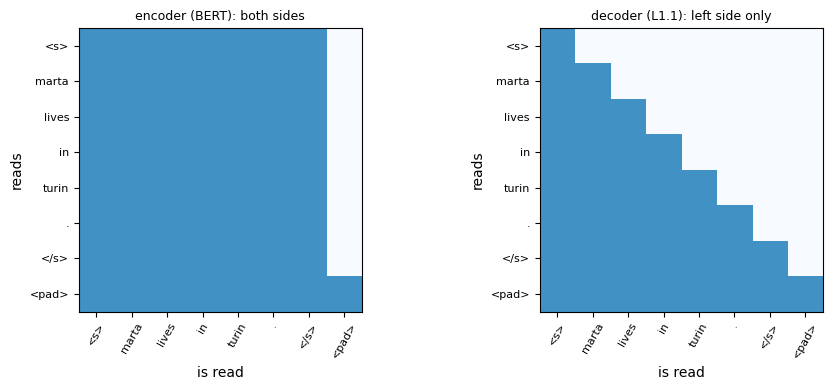

In [17]:
words = "<s> marta lives in turin . </s> <pad>".split()
tokens = torch.tensor([vocab.encode(words)])
masks = {"encoder (BERT): both sides": tinylm.TinyBERT(len(vocab)).allowed(tokens)[0],
         "decoder (L1.1): left side only": tinylm.TinyBERT(len(vocab), causal=True).allowed(tokens)[0]}
fig, axes = plt.subplots(1, 2, figsize=(9.5, 4))
for ax, (title, mask) in zip(axes, masks.items()):
    ax.imshow(mask.numpy().astype(float), cmap="Blues", vmin=0, vmax=1.6)
    ax.set_xticks(range(len(words)), words, rotation=60, fontsize=8)
    ax.set_yticks(range(len(words)), words, fontsize=8)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("is read"); ax.set_ylabel("reads")
plt.tight_layout()
plt.show()

The column of `<pad>` is empty in both panels, except for the cell in which the `<pad>` reads itself (a position always reads itself, so that no row is empty, as in L1.2): the padding is the only thing that no real word reads. This is the class that we use, with its code.

In [18]:
print(inspect.getsource(tinylm.TinyBERT.allowed))
print(inspect.getsource(tinylm.TinyBERT.encode))
print(f"parameters: {tinylm.TinyBERT(len(vocab)).n_parameters():,} (2 blocks, 2 heads, d=32, MLP 128, {len(vocab)} words)")

    def allowed(self, tokens):
        T = tokens.shape[1]
        allowed = (tokens != 0)[:, None, :].expand(-1, T, -1) | torch.eye(T, dtype=torch.bool)    # nobody reads a <pad>
        return allowed & ~torch.triu(torch.ones(T, T, dtype=torch.bool), 1) if self.causal else allowed

    def encode(self, tokens, keep_weights=False):
        x = self.embedding(tokens) + self.position(torch.arange(tokens.shape[1]))
        allowed = self.allowed(tokens)
        for block in self.blocks:
            x = block(x, allowed, keep_weights)
        return self.norm(x)

parameters: 29,751 (2 blocks, 2 heads, d=32, MLP 128, 53 words)


The class has `causal=True` as an option: it adds the triangular mask, and we use it only in Step 3, to compare the same network when it can and cannot read the right side. BERT has no such option.

### Masked language modeling

> **A simple example.** If we ask the encoder to predict the word at position $t$ and give it the whole text, it finds the word at position $t$ in its own input: it has only to copy it. For `<s> marta lives in turin . </s>`, the vector of the word `turin` can read `turin`. To make the task meaningful we have to **remove the answer** from the input: `<s> marta lives in <mask> . </s>`. The network has to say which word was there, and it can use `lives in` on the left, and anything that follows `.` on the right.
>
> The question of this section is: which words do we hide, and how? The intuition is to hide some words chosen at random, and to ask the network to find them all.

BERT hides $15\%$ of the words of each text, chosen at random (never the special tokens). Of the words that are chosen, $80\%$ are replaced with `<mask>`, $10\%$ with a random word and $10\%$ are left unchanged. The three cases have a reason: the `<mask>` symbol exists only in pre-training, never in the texts that the model will read afterwards, and the random and unchanged words oblige the network to keep a useful vector for **every** word (a word that is there could be the right one, or a wrong one that has to be corrected), not only for the masked ones. The loss is the cross-entropy of the **chosen words only**, as in L1.0 where the loss was computed on the answer only:

$$
\mathcal{L} = -\frac{1}{|S|}\sum_{t \in S} \log p\big(w_t \mid \tilde w\big), \qquad p(\cdot \mid \tilde w) = \mathrm{softmax}\big(M_t\, W_U + b\big),
$$

where $\tilde w$ is the corrupted text and $S$ the set of positions chosen. Note that the corruption is done **again at every step**: the same document is seen with different words hidden. Here is a document and its corruption with $30\%$ (to see more cases).

In [19]:
generator = torch.Generator().manual_seed(3)
original = torch.tensor([vocab.encode(train_docs[0])])
corrupted, labels = tinylm.mask_tokens(original, generator, rate=0.3, vocabulary_size=len(vocab))
chosen = (labels[0] != -100).nonzero().flatten().tolist()
pd.DataFrame({"position": chosen, "original word": [vocab.words[original[0, t]] for t in chosen],
              "input of the network": [vocab.words[corrupted[0, t]] for t in chosen]}).set_index("position").T

position,1,2,3,5,12,14,16,21,23,24,25,26
original word,mario,lives,in,.,water,diego,coffee,naples,diego,likes,yellow,.
input of the network,<mask>,<mask>,chiara,<mask>,<mask>,<mask>,<mask>,naples,<mask>,<mask>,yellow,paolo


We check the proportions on all the training documents with the rate of BERT (the "unchanged" cases include the random words that happen to be the original one, about one in fifty).

In [20]:
generator = torch.Generator().manual_seed(0)
corrupted, labels = tinylm.mask_tokens(train, generator, rate=0.15, vocabulary_size=len(vocab))
chosen = labels != -100
print(f"words chosen: {chosen.float().sum() / (train >= tinylm.FIRST_WORD).float().sum():.1%} of the words that are not special tokens")
print(f"of the chosen words: <mask> {(corrupted[chosen] == tinylm.MASK_ID).float().mean():.1%}, "
      f"unchanged {(corrupted[chosen] == train[chosen]).float().mean():.1%}, "
      f"other word {((corrupted[chosen] != train[chosen]) & (corrupted[chosen] != tinylm.MASK_ID)).float().mean():.1%}")

words chosen: 15.0% of the words that are not special tokens
of the chosen words: <mask> 79.8%, unchanged 10.3%, other word 9.9%


### The first position and the classification head

> **A simple example.** `<s> marta lives in turin . she drinks tea . </s>` is true in our world, and `<s> marta lives in rome . she drinks tea . </s>` is not: `marta` lives in turin. If we want a network that says *true* or *false* about a whole document, we need a **single vector** for the whole document, from which to read the two scores. The vector of any word knows the text (the encoder reads both sides), so we can use that of a fixed position: the first one, the same for all the documents.
>
> The question of this section is: how can an encoder that gives one vector for each word be used to classify a whole text? The intuition is to read the class from the vector of the first position, and to let training decide what that vector has to know.

In BERT the first position holds a special word, `[CLS]`, that is always there and carries no information of its own: the network can use it to collect what it needs from the rest of the text, through the attention. In our vocabulary the word that is always first is `<s>`, and it plays the same role. The classification head is a single linear layer on the vector of the first position, $M_0$:

$$
\text{scores of the classes} = M_0\, W_C + b_C.
$$

A network is used in two phases. In **pre-training** the encoder is trained on MLM, a task that needs no labels and can use as many texts as we have. In **fine-tuning** the same encoder, with its new head, is trained on the task we want, with the labelled examples that we have, and **all** the weights can change. In the real BERT the pairs of sentences are given to the network as `[CLS] sentence 1 [SEP] sentence 2 [SEP]`, and a third embedding says to which sentence a word belongs; we do not need it here, and we see it in Step 5.

Our classification task is a **verification**: given a document, say whether it is true in the world. A false document is a true one in which the value of one fact has been replaced with a wrong value. The function below prints the first document with the sentence that makes it false.

In [21]:
def wrong_sentence(document):
    for s in world.sentences(document):
        truth = world.attributes[s["person"]][s["relation"]]
        if s["value"] != truth:
            return f"{s['person']} {s['relation']}: the document says {s['value']}, the world says {truth}"

verify_docs, verify_labels = world.verification(5, 6)
for document, label in zip(verify_docs, verify_labels):
    print(f"{'TRUE ' if label else 'FALSE'}  {' '.join(document[1:-1])}")
    if not label:
        print(f"       -> {wrong_sentence(document)}")

TRUE   mario likes yellow . he is a clerk . mario lives in bari . diego is a nurse . he likes yellow . he drinks coffee .
FALSE  sara drinks juice . she lives in genoa . she likes red . giulia likes red . giulia is a baker . she drinks milk .
       -> giulia color: the document says red, the world says pink
TRUE   marta is a mechanic . she drinks tea . she lives in turin . giulia likes pink . she lives in genoa . she is a baker .
TRUE   diego lives in naples . he likes yellow . diego drinks coffee . sara likes red . she lives in genoa . she is a clerk .
TRUE   chiara lives in bari . chiara drinks cocoa . she likes red . luca is a mechanic . he likes yellow . luca lives in naples .
FALSE  chiara is a farmer . she likes red . chiara lives in bari . luca lives in naples . he drinks juice . he is a farmer .
       -> luca job: the document says farmer, the world says mechanic


## Step 3: pre-training on masked words

> **A simple example.** Take the document `<s> ____ lives in naples . he drinks coffee . he is a nurse . </s>`. A network that has learned our world knows that two people live in naples, drink coffee and are nurses, `marco` and `diego`, and it should say that the hidden name is one of the two, with about the same probability. If the document went on with `he likes brown`, only `marco` would be left. To do it, the network has to **read the facts that follow the blank**, and to know the world.
>
> The question of this section is: does a network trained only to fill in blanks learn to read the right side of the text, and what does it learn about the world? To see what the right side adds, we train two networks with the same MLM loss, one that reads both sides and one with the triangular mask, that sees only the left.

4 networks (3,000 steps of 128 documents each) in 68 s


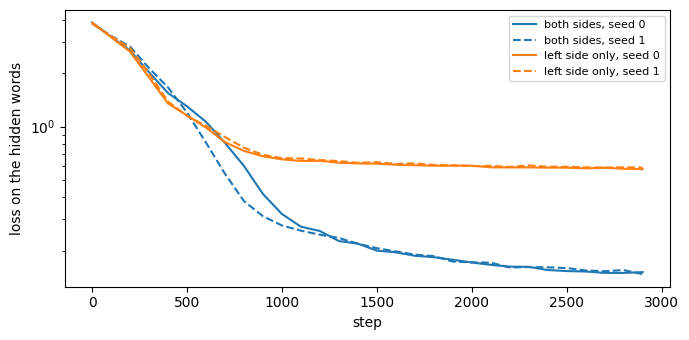

{'both sides': [0.15, 0.152], 'left side only': [0.58, 0.588]}


In [22]:
t0 = time.time()
models = {"both sides": [tinylm.fit_mlm(train, len(vocab), seed=s) for s in (0, 1)],
          "left side only": [tinylm.fit_mlm(train, len(vocab), seed=s, causal=True) for s in (0, 1)]}
print(f"4 networks (3,000 steps of 128 documents each) in {time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(7, 3.5))
for (name, nets), color in zip(models.items(), ("tab:blue", "tab:orange")):
    for seed, net in enumerate(nets):
        ax.plot(np.arange(len(net.loss_curve)) * 100, net.loss_curve, color=color, ls=("-", "--")[seed], label=f"{name}, seed {seed}")
ax.set_xlabel("step"); ax.set_ylabel("loss on the hidden words"); ax.set_yscale("log"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print({name: [round(float(net.loss_curve[-3:].mean()), 3) for net in nets] for name, nets in models.items()})

The two networks have the same parameters (29,751) and the same loss, and they start together. At about 800 steps the left-side network stops improving and stays at a loss of $0.58$ and $0.59$ (the two seeds) until the end, while the network that reads both sides continues to improve and ends at $0.15$ for both seeds. The loss is an average over all the kinds of word, so it says that **there are hidden words that the left side cannot find**, and the next tables say which ones. Note that the loss curve is a summary: it would be the same if one network were better on all the words by a little, or on a few words by a lot.

### What the network answers

We take the ambiguous document of Step 1, hide the first name, and read the probabilities that the network assigns to the people of the world. The column *fits* says whether the person is compatible with the facts.

In [23]:
i = next(i for i, d in enumerate(test_docs) if best_possible(d, 1) == 0.5)
print(" ".join(test_docs[i]), "\n")
fits = {p: p in candidates(test_docs[i], 1) for p in world.people}
answers = {}
for name, nets in models.items():
    for seed, net in enumerate(nets):
        answers[f"{name}, seed {seed}"] = tinylm.fill_blank(net, test[i:i + 1], torch.tensor([1]))[1][0]
table = pd.DataFrame({"fits": fits})
for name, probabilities in answers.items():
    table[name] = [probabilities[vocab.index[p]].item() for p in world.people]
table.sort_values("both sides, seed 0", ascending=False).head(5).style.format({c: "{:.3f}" for c in table.columns if c != "fits"})

<s> marco lives in naples . he drinks coffee . he is a nurse . luca lives in naples . he likes yellow . luca drinks juice . </s> 



,fits,"both sides, seed 0","both sides, seed 1","left side only, seed 0","left side only, seed 1"
diego,True,0.581,0.350,0.090,0.084
marco,True,0.417,0.647,0.086,0.081
paolo,False,0.000,0.000,0.079,0.083
luca,False,0.000,0.000,0.088,0.079
carlo,False,0.000,0.000,0.087,0.098


The network that reads both sides puts all the probability on the two people who fit: $0.581 + 0.417 = 0.998$ for seed 0 and $0.350 + 0.647 = 0.997$ for seed 1, and zero on everybody else, including `luca`, the other person of the document, who lives in naples too. How the probability is divided between `diego` and `marco` is **not** the same in the two seeds ($0.58$ against $0.42$, and $0.35$ against $0.65$): nothing in the document tells them apart, and the best a network can do is to be undecided, which these are not exactly. The network that reads only the left side has, at the first position, `<s>` and nothing else: it gives about $0.08$ to $0.10$ to each person of the world, close to $1/12 = 0.083$, and does not use the facts that follow. This is the case that the left side cannot solve, whatever the size of the network.

### What the network answers, by kind of word

For the test documents we hide, in turn, a word of each kind (the same positions for all the networks) and we count how often the best word of the network is the right one. The first two columns are the references of Step 1.

In [24]:
def accuracy_by_kind(net):
    out = {}
    for kind, (rows, positions) in blanks.items():
        guess, _ = tinylm.fill_blank(net, test[rows], positions)
        out[kind] = (guess == test[rows, positions]).float().mean().item()
    return out

table = pd.DataFrame(reference).T[["most frequent word", "best possible"]]
for name, nets in models.items():
    for seed, net in enumerate(nets):
        table[f"{name}, seed {seed}"] = pd.Series(accuracy_by_kind(net))
table.style.format("{:.3f}")

,most frequent word,best possible,"both sides, seed 0","both sides, seed 1","left side only, seed 0","left side only, seed 1"
name,0.071,0.985,0.980,0.978,0.090,0.080
value,0.085,1.000,1.000,1.000,1.000,1.000
pronoun,0.491,1.000,0.994,0.996,1.000,0.997
relation,0.252,1.000,1.000,0.999,0.378,0.344


For the **names**, the network that reads both sides is right $98.0\%$ and $97.8\%$ of the time, against a best possible $98.5\%$ (the difference is of five to seven documents out of 1,000, which we do not test); the network that reads the left side only is at $9.0\%$ and $8.0\%$, about the level of the most frequent name ($7.1\%$) and of a random choice ($1/12$). For the **relation words** (`drinks`, `is`, `lives`, `likes`), whose answer is given by the value on the right, we have $100\%$ and $99.9\%$ with both sides and $37.8\%$ and $34.4\%$ with the left side only, above the most frequent word ($25.2\%$): a possible reason, that we did not test, is that the three facts of a person are about three different relations, so that the previous sentences of the same person exclude some of them. For the **values** and the **pronouns** the two networks are equal ($100\%$ and $99.4$-$100\%$): the answer is in the name on the left, and the world is in the weights. This is the result that we looked for: reading the right side makes a difference **only** where the answer is on the right, and in these documents it is for the names (the name comes before its facts) and for the relation words (the value comes after the verb). A language with other word orders would give a different table.

### Where the hidden name looks

The claim that the network "reads the facts on the right" can be tested in the attention. For each test document we hide the first name and we look at the attention of that position, for each block and each head. We sum the attention that falls on the **values** of the document (cities, drinks, jobs and colours), and we separate those of the person whose name is hidden from those of the other person. If the position did not know whom it has to look at, it would divide the mass equally between the two people.

In [25]:
rows, positions = blanks["name"]
hidden = test[rows].clone()
hidden[:, 1] = tinylm.MASK_ID
own, other_person = torch.zeros(hidden.shape, dtype=torch.bool), torch.zeros(hidden.shape, dtype=torch.bool)
for r, row in enumerate(rows.tolist()):
    first = test_docs[row][1]
    for s in world.sentences(test_docs[row]):
        (own if s["person"] == first else other_person)[r, s["end"] - 1] = True

table = {}
for seed, net in enumerate(models["both sides"]):
    with torch.no_grad():
        net(hidden, keep_weights=True)
    for b, block in enumerate(net.blocks):
        weights = block.attention.weights[:, :, 1, :]                       # documents x heads x positions: the hidden name reads
        mass_own, mass_other = (weights * own[:, None]).sum(-1), (weights * other_person[:, None]).sum(-1)
        for h in range(weights.shape[1]):
            table[(f"seed {seed}", f"block {b + 1}, head {h + 1}")] = {
                "attention on values": (mass_own + mass_other)[:, h].mean().item(),
                "share on the values of its own person": (mass_own[:, h] / (mass_own + mass_other)[:, h]).mean().item()}
pd.DataFrame(table).T.style.format("{:.2f}")

In the second block the hidden name puts $72\%$ to $78\%$ of its attention on values, and almost all of it on the values of its own person: the share is $0.99$ or $1.00$ in the four heads of the two seeds, where $0.5$ would mean that the two people are not distinguished. The first block is more varied: one head of each seed has a low mass on the values ($0.19$ and $0.20$, they must be reading other words), and the share on the values of its own person is $0.90$ to $0.97$. A reading of this table needs some care: the hidden name is always the first word of the document, so the sentences about its person are the **first** ones, and the position alone could give a part of this result; we do not separate the two things. Moreover, the attention says where a position **reads**, not what is used: this is the lesson of L1.0 (the seed 0 of the second layer) and of L1.2, and the ablation of a head would be the way to test it.

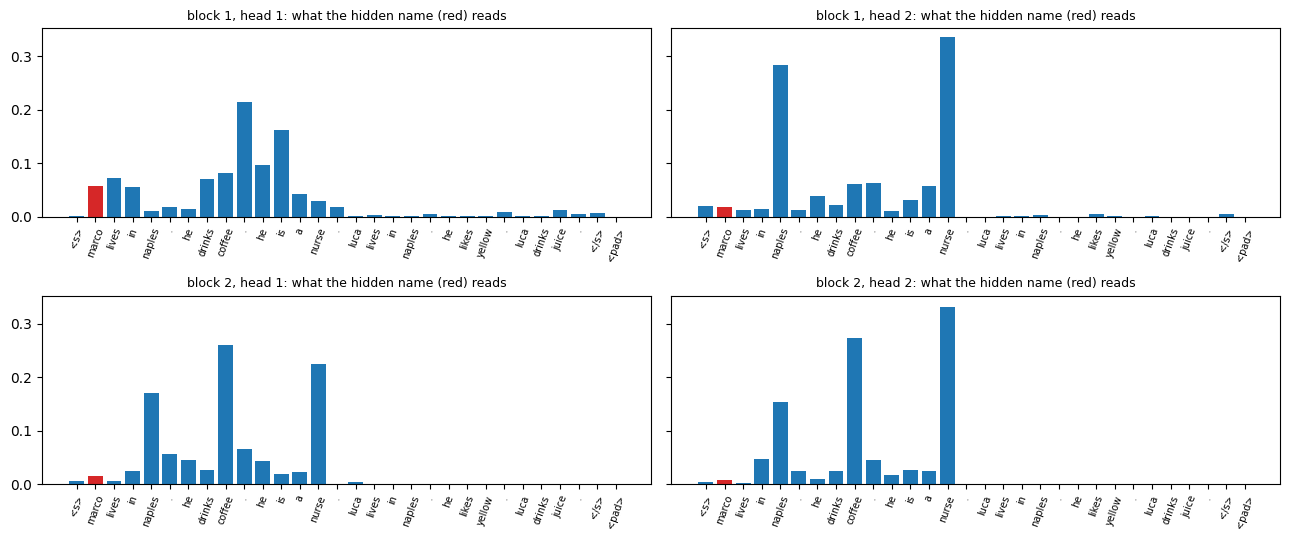

In [26]:
net = models["both sides"][0]
x = test[i:i + 1].clone()
x[0, 1] = tinylm.MASK_ID
with torch.no_grad():
    net(x, keep_weights=True)
fig, axes = plt.subplots(2, 2, figsize=(13, 5.5), sharey=True)
for b, block in enumerate(net.blocks):
    for h in range(block.attention.weights.shape[1]):
        ax = axes[b, h]
        weights = block.attention.weights[0, h, 1]
        ax.bar(range(len(weights)), weights, color=["tab:red" if t == 1 else "tab:blue" for t in range(len(weights))])
        ax.set_xticks(range(len(weights)), vocab.decode(test[i].tolist()), rotation=70, fontsize=7)
        ax.set_title(f"block {b + 1}, head {h + 1}: what the hidden name (red) reads", fontsize=9)
plt.tight_layout()
plt.show()

In the example of Step 1 (the hidden name is `marco`; the other person of the document is `luca`) the two heads of the second block put the attention on `naples`, `coffee` and `nurse`, with about $0.15$ to $0.35$ each, and nothing on the facts of `luca` (`lives in naples`, `likes yellow`, `drinks juice`), although `luca` lives in naples too. In the first block the heads are less sharp: head 2 is on `naples` and `nurse`, head 1 on `coffee` and on the words `drinks`, `he`, `is` of the same person. One example, one seed: it is an illustration of the table above, not a measure.

## Step 4: fine-tuning for classification

> **A simple example.** We have a few documents of our world, each one labelled `true` or `false`, and we want a network that labels a new one. A network that has never seen the world has to discover it from the labels, one document at a time: from a false `marta lives in rome` it learns little, because it does not know which part of the sentence is wrong. A network that has already learned to fill in the blanks has seen thousands of documents and knows where `marta` lives: it may need only to be told that a document of the kind "something does not fit" is called `false`.
>
> The question of this section is: does pre-training make the labelled examples go further? The intuition is that the unlabelled documents teach the world, and the labelled ones only have to teach the task. We compare three networks, with 2,000, 5,000 and 20,000 labelled documents (half true, half false): the **same architecture from scratch**; the **pre-trained** encoder with all its weights **fine-tuned**; the pre-trained encoder with **only the head trained** (the weights of the encoder stay as they were after the MLM). The test is a set of 2,000 new documents, half true and half false.

In [27]:
verify_train_docs, verify_train_labels = world.verification(1, 20000)
verify_test_docs, verify_test_labels = world.verification(999, 2000)
verify_train, verify_y = torch.tensor(vocab.batch(verify_train_docs)), torch.tensor(verify_train_labels)
verify_test, verify_test_y = torch.tensor(vocab.batch(verify_test_docs)), torch.tensor(verify_test_labels)

t0 = time.time()
results, tuned = [], {}
for n in (2000, 5000, 20000):
    for start in ("from scratch", "fine-tuned", "head only"):
        for seed in (0, 1):
            init = None if start == "from scratch" else models["both sides"][seed].state_dict()
            net = tinylm.fit_classifier(verify_train[:n], verify_y[:n], len(vocab), init=init, freeze=(start == "head only"), seed=seed, steps=2000)
            results.append({"labelled documents": n, "start": start, "seed": seed,
                            "train": tinylm.class_accuracy(net, verify_train[:n], verify_y[:n]),
                            "test": tinylm.class_accuracy(net, verify_test, verify_test_y)})
            if start == "fine-tuned" and n == 20000:
                tuned[seed] = net
results = pd.DataFrame(results)
print(f"18 networks (2,000 steps of 64 documents each) in {time.time() - t0:.0f} s\n")
print("accuracy on the test documents")
display(results.pivot_table(index=["start", "seed"], columns="labelled documents", values="test").style.format("{:.3f}"))
print("accuracy on the labelled documents used for training")
display(results.pivot_table(index=["start", "seed"], columns="labelled documents", values="train").style.format("{:.3f}"))

18 networks (2,000 steps of 64 documents each) in 147 s

accuracy on the test documents


accuracy on the labelled documents used for training


With **2,000 labelled documents** the pre-trained encoder is better than the network from scratch for seed 0 ($0.865$ against $0.605$) and not for seed 1 ($0.576$ against $0.567$). With **5,000** it is better in both seeds ($0.985$ and $0.830$ against $0.661$ and $0.691$) and with **20,000** the fine-tuned networks are at $0.996$ and $0.928$, the networks from scratch at $0.733$ and $0.790$. The two kinds of start fail in two different ways, that the table of the training accuracy shows: from scratch with 2,000 documents the network **memorizes** (training $0.988$ and $0.997$, test $0.605$ and $0.567$), and with 20,000 it does not even fit the training documents in 2,000 steps (training $0.748$ and $0.795$). We do not know why the learning from the labels alone is so slow; a hypothesis is that each label gives one bit about a whole document, and the network has to learn the world, the facts of which only a small part is wrong in each false document. Two tests outside the notebook: the network from scratch with 8,000 steps on 5,000 documents (one seed) is at $0.70$, so it is not only a matter of steps; the fine-tuned network of seed 1 with 3,000 steps on 20,000 documents is at $0.98$, so its $0.928$ is the result of too short a training. **The seed of the pre-training matters** (the two pre-trained encoders are two different starting points), and with two seeds we cannot say more. The network with **only the head trained** is at $0.52$ to $0.55$ at all sizes, that is chance: the vector of the first position, in an encoder trained on MLM, does not contain the truth of the document. This is not surprising: `<s>` is never hidden, so no loss has ever asked its vector to summarize anything. It is the pre-training of the original BERT on a second task, on the vector of `[CLS]` (next sentence prediction), that gave this position a meaning; the fine-tuning does not need it, as the other rows show.

### What the fine-tuned network knows

The fine-tuned network reads the first position and says *true* or *false*. In L1.2 we saw that a network trained on a single world writes the facts of that world and does not read the source; the same may be true here, and we can test it. We build a second world (seed 50: same people and same values, other facts) and we give the network true and false documents of that world; for comparison, the test documents of our world. We also hide a value in the documents of the new world and we ask the pre-trained encoder to find it: is the answer the value of the new world, or the value that our world gives to that person?

In [28]:
new_world = toyworld.ToyWorld(toyworld.WorldConfig(seed=50))
new_docs, new_labels = new_world.verification(7, 2000)
new_tokens, new_y = torch.tensor(vocab.batch(new_docs)), torch.tensor(new_labels)

rows = []
for seed, net in tuned.items():
    for name, (tokens, y) in {"our world": (verify_test, verify_test_y), "new world": (new_tokens, new_y)}.items():
        with torch.no_grad():
            called_true = (net.classify(tokens).argmax(-1) == 1).float()
        rows.append({"seed": seed, "documents of": name, "true documents called true": called_true[y == 1].mean().item(),
                     "false documents called true": called_true[y == 0].mean().item()})
display(pd.DataFrame(rows).set_index(["seed", "documents of"]).style.format("{:.3f}"))

rng = np.random.default_rng(0)
new_documents = new_world.documents(11, 1000, n_people=2, n_facts=3)
positions, answers_new, answers_ours = [], [], []
for document in new_documents:
    sentence = new_world.sentences(document)[int(rng.integers(len(new_world.sentences(document))))]
    positions.append(sentence["end"] - 1)
    answers_new.append(sentence["value"])
    answers_ours.append(world.attributes[sentence["person"]][sentence["relation"]])
guess, _ = tinylm.fill_blank(models["both sides"][0], torch.tensor(vocab.batch(new_documents)), torch.tensor(positions))
guess = [vocab.words[g] for g in guess.tolist()]
print(f"\nhidden value in {len(new_documents)} documents of the new world, pre-trained network (seed 0):")
print(f"  equal to the value of the new world: {np.mean([g == a for g, a in zip(guess, answers_new)]):.1%}")
print(f"  equal to the value that our world gives to that person: {np.mean([g == a for g, a in zip(guess, answers_ours)]):.1%}")
print(f"  (the two worlds agree on {np.mean([a == b for a, b in zip(answers_new, answers_ours)]):.1%} of these facts)")


hidden value in 1000 documents of the new world, pre-trained network (seed 0):
  equal to the value of the new world: 4.1%
  equal to the value that our world gives to that person: 95.9%
  (the two worlds agree on 3.6% of these facts)


On the test documents of our world the fine-tuned networks say *true* to $100\%$ and $99.1\%$ of the true documents and to $0.9\%$ and $13.6\%$ of the false ones (the second network is the one with the weaker $0.928$). On the documents of the new world they say *true* to **none** of the true ones: $0.0\%$ for both. They are not wrong in their own terms: nearly all the facts of the new world are false in ours (the two worlds agree on 2 of the 48 facts), and they answer for our world. The same happens to the pre-trained encoder when we hide a value in a document of the new world: its answer is the value that **our** world gives to the person in $95.9\%$ of the cases, and the value of the new world in $4.1\%$ (the two worlds agree on $3.6\%$ of the sampled facts, which is about the share of the $4.1\%$). The pre-trained network does not use the other facts of the document to find the value: it has learned the world, and in this document the value cannot be found by reading. This is the same lesson as L1.2: the accuracy in the world of training does not tell whether a network *reads* or *remembers*, and the weights of a pre-trained model are a snapshot of what it has read. It is a limit of the toy, where the world is one and small, and it is also the case with the real models, where the snapshot is the web of the date of the training; we meet it again in L2 and L3.

## Step 5: the real BERT

> **A simple example.** Our network knows who drinks tea in a world of twelve people. A real BERT knows who wrote *Hamlet*, which city is the capital of France and how to conjugate a verb, because it has read billions of words; but if we ask it `anna drinks tea and lives in ____` it knows nothing of our `anna`, and it will answer with a city of the real world.
>
> The question of this section is: what is the same in the real model and what is not? The intuition is that **the recipe is the same** (encoder, MLM on both sides, a head on the first position), and that what changes is the scale and a few details of the input. We use `bert-base-uncased` (Devlin et al., 2019), that is already in the Hugging Face cache of this course.

In [1]:
# Step 5 is self-contained: it can be run on its own, without the cells above
import pandas as pd
import matplotlib.pyplot as plt
import torch
from nlp import toyworld, tinylm

vocab = toyworld.ToyWorld().vocabulary()         # only to build the toy network of the comparison

from transformers import AutoTokenizer, AutoModelForMaskedLM, AutoModelForQuestionAnswering
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModelForMaskedLM.from_pretrained("bert-base-uncased", attn_implementation="eager").eval()
config, toy = bert.config, tinylm.TinyBERT(len(vocab))
pd.DataFrame({
    "our network": [len(toy.blocks), toy.embedding.embedding_dim, toy.blocks[0].attention.heads, toy.blocks[0].mlp.up.out_features, len(vocab), toy.position.num_embeddings, toy.n_parameters()],
    "bert-base-uncased": [config.num_hidden_layers, config.hidden_size, config.num_attention_heads, config.intermediate_size, config.vocab_size, config.max_position_embeddings, sum(p.numel() for p in bert.parameters())]},
    index=["blocks", "dimension d", "heads", "width of the MLP", "words in the vocabulary", "positions", "parameters"]).style.format("{:,}")

,our network,bert-base-uncased
blocks,2,12
dimension d,32,768
heads,2,12
width of the MLP,128,"3,072"
words in the vocabulary,53,"30,522"
positions,32,512
parameters,"29,751","109,514,298"


The real model is about 3,700 times larger (109.5 million parameters against 29.8 thousand; of them, $30{,}522 \times 768 = 23.4$ million are the embeddings of the pieces, and the count includes the head of MLM, as ours does). The recipe has the same pieces: embeddings of words and positions, blocks of self-attention and MLP, a final head. The attention of BERT has 12 heads of dimension 64, ours has 2 heads of dimension 16.

### The input of the real BERT

The words of BERT are not whole words but **pieces** of words (WordPiece, a method of the same family as the BPE that we see in L1.4): a rare word is split in pieces, a common one stays whole. The sequence always starts with `[CLS]`, and a pair of texts is given as `[CLS] text 1 [SEP] text 2 [SEP]`. A third embedding, added to the word and to the position, says whether a word belongs to the first text (0) or to the second (1): these are the `token_type_ids`. The pair is what allows tasks such as *does the second sentence follow from the first?* (natural language inference), or *where is the answer to this question in this text?*.

In [2]:
print(tokenizer.tokenize("Marco drinks cappuccino and lives in Turin."), "\n")
pair = tokenizer("Marco drinks coffee.", "He lives in Rome.", return_tensors="pt")
pd.DataFrame({"token": tokenizer.convert_ids_to_tokens(pair["input_ids"][0]), "token_type_id": pair["token_type_ids"][0].tolist()}).T

['marco', 'drinks', 'cap', '##pu', '##cci', '##no', 'and', 'lives', 'in', 'turin', '.'] 



,0,1,2,3,4,5,6,7,8,9,10,11
token,[CLS],marco,drinks,coffee,.,[SEP],he,lives,in,rome,.,[SEP]
token_type_id,0,0,0,0,0,0,1,1,1,1,1,1


### Filling in a blank with the real BERT

We ask the real model for the hidden word in four sentences. The first two say the same thing, with the blank on the left in one and on the right in the other. The last two are about our toy world.

In [31]:
def fill(sentence, top=4):
    x = tokenizer(sentence, return_tensors="pt")
    blank = (x["input_ids"][0] == tokenizer.mask_token_id).nonzero()[0].item()
    with torch.no_grad():
        probabilities = bert(**x).logits[0, blank].softmax(-1)
    best = probabilities.topk(top)
    return ", ".join(f"{tokenizer.decode(i)} {p:.2f}" for p, i in zip(best.values, best.indices))

for sentence in ["[MASK] was born in 1879 and developed the theory of relativity.",
                 "The theory of relativity was developed by [MASK], who was born in 1879.",
                 "Anna drinks tea and lives in [MASK].",
                 "[MASK] drinks tea and lives in Rome."]:
    print(f"{sentence}\n   -> {fill(sentence)}\n")

[MASK] was born in 1879 and developed the theory of relativity.
   -> he 0.62, einstein 0.24, newton 0.01, bose 0.00

The theory of relativity was developed by [MASK], who was born in 1879.
   -> einstein 0.92, newton 0.00, jung 0.00, bose 0.00

Anna drinks tea and lives in [MASK].
   -> london 0.19, paris 0.05, england 0.04, switzerland 0.03

[MASK] drinks tea and lives in Rome.
   -> she 0.54, he 0.37, it 0.00, julia 0.00



With the blank on the left (first sentence) the model puts $0.62$ on `he` and $0.24$ on `einstein`: it knows that a person is missing, and the right context (*born in 1879*, *developed the theory of relativity*) tells it that it is a male person, but it does not decide for the name. With the blank in the middle (second sentence) the answer is `einstein` with $0.92$. We do not know why the two sentences differ so much; a plausible reason is that a pronoun is a likely beginning of a sentence, and the second sentence makes a pronoun unlikely, but it is a reading, not a test. On our toy sentences the real model answers with what it knows: a city of the real world for `anna` ($0.19$ for `london`; `milan`, the city of our `anna`, is not among the first four) and a pronoun for the missing name ($0.54$ `she`, $0.37$ `he`), where our network used the world to name the person. The two models know different things: the real one knows the language and the real world, ours knows its world and nothing more.

### Where the real BERT looks

In the toy the hidden name reads the values of its person, and we read it in a bar chart. We ask the same question to the real model: for the `[MASK]` of each of the four sentences above, how much attention (averaged over the 12 heads) falls on `[CLS]`, `[SEP]` and the full stop in each layer?

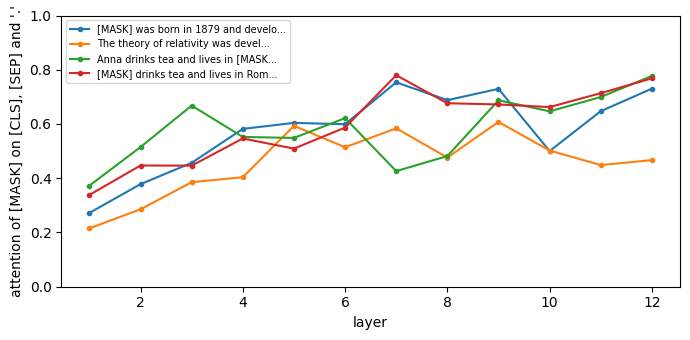

In [4]:
sentences = ["[MASK] was born in 1879 and developed the theory of relativity.",
             "The theory of relativity was developed by [MASK], who was born in 1879.",
             "Anna drinks tea and lives in [MASK].",
             "[MASK] drinks tea and lives in Rome."]
fig, ax = plt.subplots(figsize=(7, 3.5))
for sentence in sentences:
    x = tokenizer(sentence, return_tensors="pt")
    blank = (x["input_ids"][0] == tokenizer.mask_token_id).nonzero()[0].item()
    pieces = tokenizer.convert_ids_to_tokens(x["input_ids"][0])
    boring = torch.tensor([p in ("[CLS]", "[SEP]", ".") for p in pieces])
    with torch.no_grad():
        attentions = bert.bert(**x, output_attentions=True).attentions
    ax.plot(range(1, 13), [a[0].mean(0)[blank][boring].sum().item() for a in attentions], marker="o", ms=3, label=sentence[:34] + "...")
ax.set_xlabel("layer"); ax.set_ylabel("attention of [MASK] on [CLS], [SEP] and '.'"); ax.set_ylim(0, 1); ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

In the first layer $22\%$ to $37\%$ of the attention of `[MASK]` is on `[CLS]`, `[SEP]` and the full stop; in the last layer, $47\%$ to $78\%$, and in the layers from 7 to 12 it is between $0.43$ and $0.78$ in all the four sentences. The figure is averaged over the 12 heads of each layer and says nothing about single heads; with four sentences it is an observation, not a measure. It matches what is reported in the literature on BERT (Clark et al., 2019, for the heads that attend to `[SEP]` and to punctuation, which they interpret as a way to do nothing) and it tells us what is different from the toy: in our network the hidden name puts most of its attention on the facts of its person; in the real network a large part of the attention is on tokens that carry no content, and the reading that the model does is spread on many heads and layers. It is also the reason why the attention maps of a real model are **harder to read** than the ones of this notebook.

### Looking at the heads with BertViz

The bar chart above is an average over the 12 heads of a layer. To see the **single heads** we use [BertViz](https://github.com/jessevig/bertviz), a tool that draws the attention of a transformer as lines between the words. For the first sentence we get one view with all the heads: choose a layer in the menu, click a colored square at the top to select (or hide) a head, and move the mouse over a word on the left to see where it looks; the thicker the line, the larger the attention. Try the `[MASK]` in the last layers: some heads send everything to `[SEP]` and to the full stop, as in the chart, and others spread the attention over `theory`, `relativity` and `1879`.

In [5]:
from bertviz import head_view

sentence = "[MASK] was born in 1879 and developed the theory of relativity."
x = tokenizer(sentence, return_tensors="pt")
with torch.no_grad():
    attention = bert(**x, output_attentions=True).attentions      # 12 layers, each (1, 12 heads, tokens, tokens)
head_view(attention, tokenizer.convert_ids_to_tokens(x["input_ids"][0]))

<IPython.core.display.Javascript object>

### A head for every task

The recipe of fine-tuning is the same as ours: a small head on top of the encoder, and all the weights trained on the labelled examples. For a classification of a text or of a pair (for example natural language inference, with a pair of texts and three classes) the head reads the vector of `[CLS]`, as ours does. For *extractive question answering* the head is different: for **every word of the text** it gives two scores, *is this the first word of the answer?* and *is this the last one?*, and the answer is the stretch between the best start and the best end. The question and the text are given as a pair. A BERT fine-tuned on SQuAD (Rajpurkar et al., 2016) is in the cache: we ask it about the facts of our toy world, written in a text.

In [34]:
name = "csarron/bert-base-uncased-squad-v1"
qa_tokenizer, qa = AutoTokenizer.from_pretrained(name), AutoModelForQuestionAnswering.from_pretrained(name).eval()
text = "Marco drinks coffee and lives in Rome. Anna drinks tea and lives in Milan."
for question in ["Where does Anna live?", "Who drinks coffee?", "What does Anna drink?", "Where does Marco live?"]:
    x = qa_tokenizer(question, text, return_tensors="pt")
    with torch.no_grad():
        out = qa(**x)
    start, end = out.start_logits.argmax().item(), out.end_logits.argmax().item()
    print(f"{question:25s} -> {qa_tokenizer.decode(x['input_ids'][0][start:end + 1])}")

Where does Anna live?     -> milan
Who drinks coffee?        -> marco
What does Anna drink?     -> tea
Where does Marco live?    -> rome


The model finds the right words in the four questions (`milan`, `marco`, `tea`, `rome`), in a text that it has never seen, about people who do not exist: unlike our toy, that knows its world and does not read a new one, this model **reads** the text it is given. Four questions are an illustration and not a measure of the model.

## Conclusions and what changes with the real models

What we saw in the toy:

1. **An encoder is the blocks of L1.2 with a mask that hides nothing.** What an encoder can do and a decoder cannot is to give a word a vector that knows the words that follow it. We saw it where it matters, with a hidden name that is identified only by the facts on its right.
2. **Masked language modeling needs no labels**: the text is its own label, and a network trained to fill in blanks learns the world of the texts that it reads (here, who drinks what and who lives where).
3. **Fine-tuning** adds a head on the first position and trains all the weights on a small task. In the toy the pre-trained encoder made the labelled examples go further, and the head alone on a frozen encoder was not enough.
4. **What the model knows is what it has read**: the knowledge is in the weights, it is the one of the world of pre-training, and it does not follow the documents that we give to the network afterwards.

What changes with the real models (from the BERT paper and the later literature, not from our experiments):

* **Scale and data.** BERT-base has 12 blocks, $d=768$ and 12 heads, about 110 million parameters, and was pre-trained on BooksCorpus and English Wikipedia (about 3.3 billion words). Our network has 30 thousand parameters and a world of twelve people.
* **The input.** WordPiece pieces instead of whole words, `[CLS]` and `[SEP]`, a third embedding for the two segments of a pair, learned position embeddings up to 512 positions.
* **A second pre-training task.** The original BERT was also trained on *next sentence prediction* (given two sentences, is the second the one that follows the first in the text?), with a head on `[CLS]`. Later works (RoBERTa, Liu et al., 2019) found that it can be dropped and that more data and longer training matter more.
* **Small details of the block.** The original BERT has the layer normalization *after* the residual connection (post-LN) and the GELU in the MLP; we use the pre-LN of L1.1, that is the form of the recent models.
* **What emerges.** Studies of the vectors and of the heads of BERT (for example Tenney et al., 2019; Clark et al., 2019) found that the layers organize themselves in an order that resembles the steps of a classical pipeline (word class, syntax, meaning) and that many heads attend to `[SEP]` and to punctuation. The second finding is the one that we saw in the last plot; the first needs probes that we do not have in the toy.

The encoder gives vectors for understanding, not words for writing. In L1.4 we go the other way: the same blocks with the triangular mask, trained to predict the next word, are a model that **generates** (GPT). We compare it with the encoder-decoder of L1.2 on the same translation, and we see what is needed to make it write.